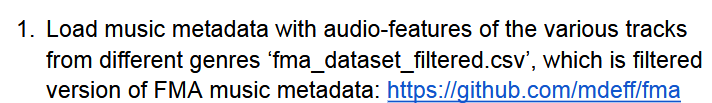

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('./fma_dataset_filtered.csv', header = 0)
df.head()

,track_id,chroma_cens_kurtosis_01,chroma_cens_kurtosis_02,chroma_cens_kurtosis_03,chroma_cens_kurtosis_04,chroma_cens_kurtosis_05,chroma_cens_kurtosis_06,chroma_cens_kurtosis_07,chroma_cens_kurtosis_08,chroma_cens_kurtosis_09,...,zcr_mean_01,zcr_median_01,zcr_min_01,zcr_skew_01,zcr_std_01,duration,tempo,danceability,energy,genre
0,2,7.180653,5.230309,0.249321,1.347620,1.482478,0.531371,1.481593,2.691455,0.866868,...,0.085629,0.071289,0.000000,2.089872,0.061448,168,165.922,0.675894,0.634476,Hip-Hop
1,3,1.888963,0.760539,0.345297,2.295201,1.654031,0.067592,1.366848,1.054094,0.108103,...,0.084578,0.063965,0.000000,1.716724,0.069330,237,126.957,0.528643,0.817461,Hip-Hop
2,5,0.527563,-0.077654,-0.279610,0.685883,1.937570,0.880839,-0.923192,-0.927232,0.666617,...,0.053114,0.041504,0.000000,2.193303,0.044861,206,100.260,0.745566,0.701470,Hip-Hop
3,134,0.918445,0.674147,0.577818,1.281117,0.933746,0.078177,1.199204,-0.175223,0.925482,...,0.064370,0.050781,0.000000,1.806106,0.054623,207,114.290,0.513238,0.560410,Hip-Hop
4,139,-0.020869,0.432330,0.331278,0.829845,2.625593,2.005660,0.907704,0.748191,1.560385,...,0.070760,0.066895,0.000977,0.769163,0.030017,296,196.961,0.260911,0.607067,Folk


In [48]:
df = df.drop(columns='track_id')
x = df.iloc[:, :-1]
y = df.iloc[:, -1]
x.head()



,chroma_cens_kurtosis_01,chroma_cens_kurtosis_02,chroma_cens_kurtosis_03,chroma_cens_kurtosis_04,chroma_cens_kurtosis_05,chroma_cens_kurtosis_06,chroma_cens_kurtosis_07,chroma_cens_kurtosis_08,chroma_cens_kurtosis_09,chroma_cens_kurtosis_10,...,zcr_max_01,zcr_mean_01,zcr_median_01,zcr_min_01,zcr_skew_01,zcr_std_01,duration,tempo,danceability,energy
0,7.180653,5.230309,0.249321,1.347620,1.482478,0.531371,1.481593,2.691455,0.866868,1.341231,...,0.459473,0.085629,0.071289,0.000000,2.089872,0.061448,168,165.922,0.675894,0.634476
1,1.888963,0.760539,0.345297,2.295201,1.654031,0.067592,1.366848,1.054094,0.108103,0.619185,...,0.466309,0.084578,0.063965,0.000000,1.716724,0.069330,237,126.957,0.528643,0.817461
2,0.527563,-0.077654,-0.279610,0.685883,1.937570,0.880839,-0.923192,-0.927232,0.666617,1.038546,...,0.375000,0.053114,0.041504,0.000000,2.193303,0.044861,206,100.260,0.745566,0.701470
3,0.918445,0.674147,0.577818,1.281117,0.933746,0.078177,1.199204,-0.175223,0.925482,1.438509,...,0.419434,0.064370,0.050781,0.000000,1.806106,0.054623,207,114.290,0.513238,0.560410
4,-0.020869,0.432330,0.331278,0.829845,2.625593,2.005660,0.907704,0.748191,1.560385,2.565748,...,0.261230,0.070760,0.066895,0.000977,0.769163,0.030017,296,196.961,0.260911,0.607067


In [49]:
y.head()

0    Hip-Hop
1    Hip-Hop
2    Hip-Hop
3    Hip-Hop
4       Folk
Name: genre, dtype: str

In [50]:
x = StandardScaler().fit_transform(x)
x = pd.DataFrame(x, columns=df.columns[:-1])
x.head()

,chroma_cens_kurtosis_01,chroma_cens_kurtosis_02,chroma_cens_kurtosis_03,chroma_cens_kurtosis_04,chroma_cens_kurtosis_05,chroma_cens_kurtosis_06,chroma_cens_kurtosis_07,chroma_cens_kurtosis_08,chroma_cens_kurtosis_09,chroma_cens_kurtosis_10,...,zcr_max_01,zcr_mean_01,zcr_median_01,zcr_min_01,zcr_skew_01,zcr_std_01,duration,tempo,danceability,energy
0,3.763350,4.802694,0.149462,1.294600,0.935749,0.500832,1.245515,1.904060,0.683259,1.111415,...,0.552435,1.109582,1.011679,-0.516662,-0.469370,1.021568,-0.312745,1.382178,0.995706,1.130052
1,0.965237,0.762063,0.213381,2.157781,1.044804,0.097596,1.152987,0.752128,0.127183,0.544318,...,0.593891,1.076329,0.764091,-0.516662,-0.600209,1.347216,-0.023610,0.332919,0.205530,1.855755
2,0.245363,0.004344,-0.202802,0.691804,1.225047,0.804679,-0.693649,-0.641793,0.536501,0.873686,...,0.040158,0.080782,0.004823,-0.516662,-0.433103,0.336255,-0.153511,-0.385984,1.369578,1.395743
3,0.452051,0.683965,0.368239,1.234021,0.586925,0.106799,1.017803,-0.112733,0.726215,1.187818,...,0.309621,0.436910,0.318434,-0.516662,-0.568869,0.739583,-0.149321,-0.008181,0.122864,0.836310
4,-0.044634,0.465364,0.204045,0.822944,1.662418,1.782664,0.782744,0.536916,1.191516,2.073156,...,-0.649788,0.639106,0.863126,-0.328258,-0.932458,-0.277027,0.223622,2.218004,-1.231169,1.021348


# PCA

In [51]:
pca = PCA(n_components=2).fit_transform(x)
pca = pd.DataFrame(pca, columns=['pc_1', 'pc_2'])
pca.head()

,pc_1,pc_2
0,-7.685345,-0.759378
1,-10.188710,1.699713
2,-6.898331,1.583611
3,-8.947768,3.961555
4,-5.512513,-4.259630


<Axes: xlabel='pc_1', ylabel='pc_2'>

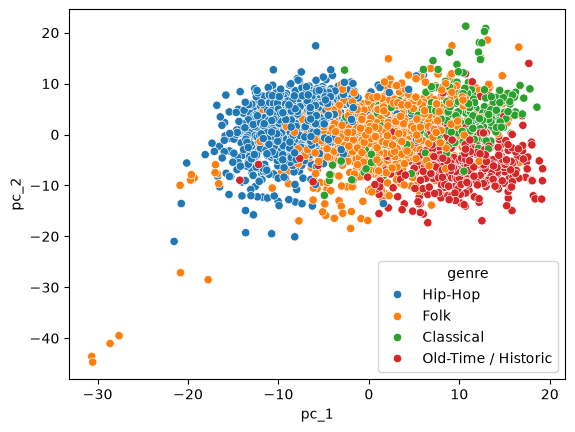

In [52]:
sns.scatterplot(x ='pc_1', y = 'pc_2', data=pca, hue=y)

# tSNE

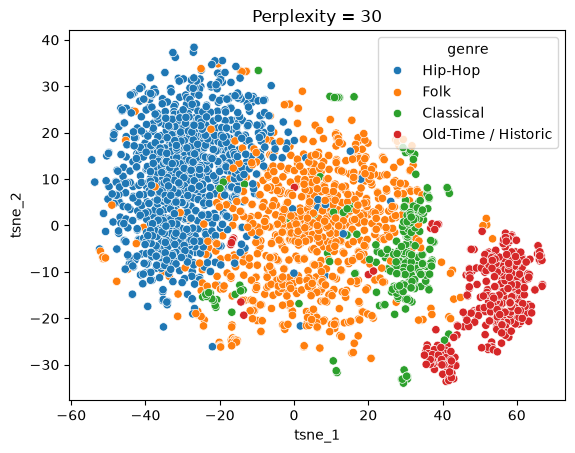

In [77]:

tsne = TSNE(perplexity=30).fit_transform(x)
tsne = pd.DataFrame(tsne, columns=['tsne_1', 'tsne_2'])

sns.scatterplot(x = 'tsne_1', y = 'tsne_2', data=tsne, hue=y)
plt.title('Perplexity = {0}'.format(30))
plt.show()

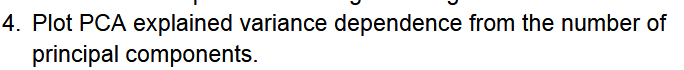

In [78]:
x.shape

(2406, 522)

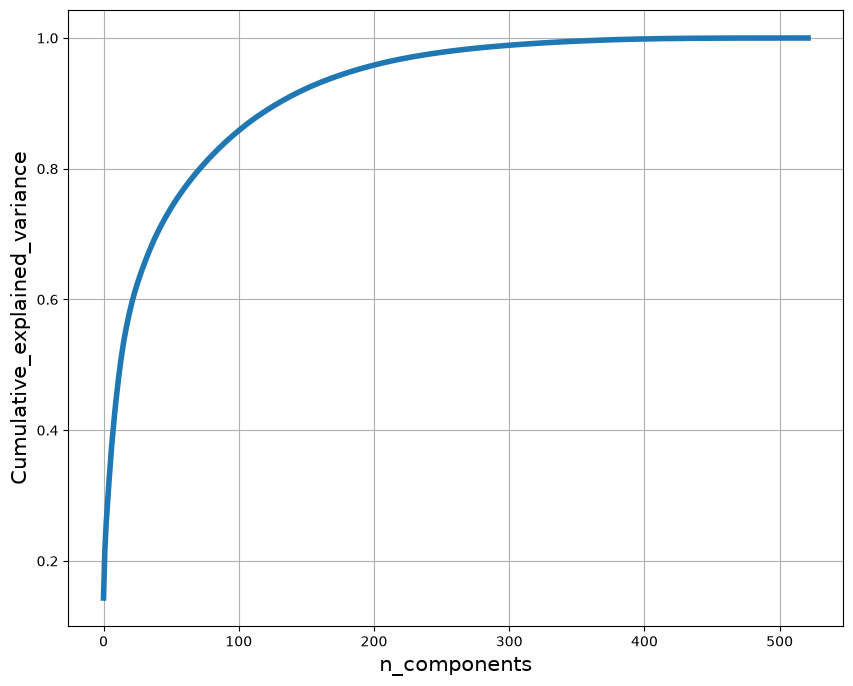

2D -  0.25799223781325364


In [79]:
from sklearn import decomposition
pca = decomposition.PCA()

pca.n_components = 522
pca_data = pca.fit_transform(x)

percentage_var_explained = pca.explained_variance_ / np.sum(pca.explained_variance_)

cum_var_explained = np.cumsum(percentage_var_explained)

# Plot the PCA spectrum
plt.figure(figsize=(10, 8))
plt.plot(cum_var_explained, linewidth=4)
plt.axis('tight')
plt.grid()
plt.xlabel('n_components', size=15)
plt.ylabel('Cumulative_explained_variance', size=15)
plt.show()

# If we take 2-dimensions, approx. 26% of variance is expalined.
print("2D - ", cum_var_explained[2])

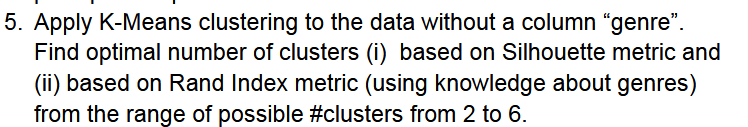

k = 2, Silhouette Score = 0.1096
k = 2, rand Score = 0.6803
k = 3, Silhouette Score = 0.0899
k = 3, rand Score = 0.7856
k = 4, Silhouette Score = 0.0756
k = 4, rand Score = 0.7740
k = 5, Silhouette Score = 0.0718
k = 5, rand Score = 0.8047
k = 6, Silhouette Score = 0.0721
k = 6, rand Score = 0.8048


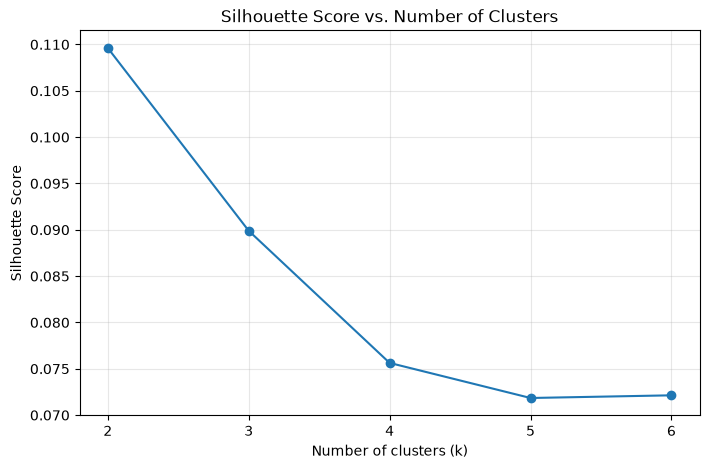

Optimal number of Clusters based on Silhouette Score is 2


In [86]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.metrics import rand_score
from sklearn.preprocessing import StandardScaler



X_scaled = x

# Evaluate different numbers of clusters
k_values = range(2, 7 )
silhouette_scores = []
rand_scores = []
best_k_sil = 1
best_sil_score = 0
best_k_rand = 1
best_r_score = 0

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    r_score = rand_score(y, labels)
    silhouette_scores.append(score)
    rand_scores.append(r_score)
    
    if best_sil_score < score:
        best_sil_score =score
        best_k_sil = k
    if best_r_score < r_score:
        best_r_score = r_score
        best_k_rand = k

    print(f"k = {k}, Silhouette Score = {score:.4f}")
    print(f"k = {k}, rand Score = {r_score:.4f}")

# Plot the results
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker='o')
plt.xticks(list(k_values))
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs. Number of Clusters")
plt.grid(True, alpha=0.3)
plt.show()
print("Optimal number of Clusters based on Silhouette Score is", best_k_sil)

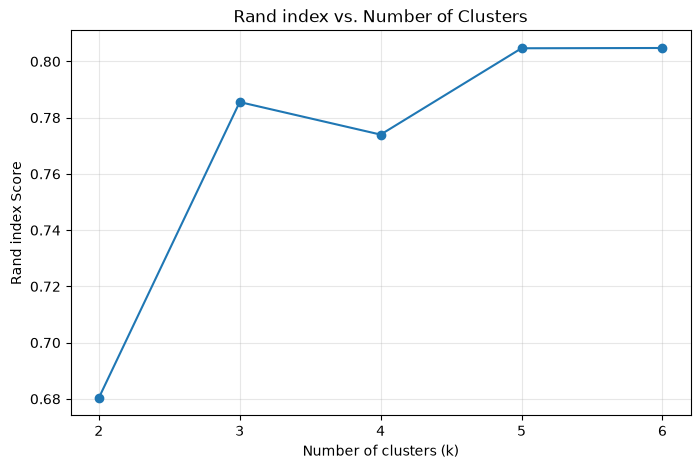

Optimal number of Clusters based on Rand index Score is 6


In [87]:

# Plot the results
plt.figure(figsize=(8, 5))
plt.plot(k_values, rand_scores, marker='o')
plt.xticks(list(k_values))
plt.xlabel("Number of clusters (k)")
plt.ylabel("Rand index Score")
plt.title("Rand index vs. Number of Clusters")
plt.grid(True, alpha=0.3)
plt.show()
print("Optimal number of Clusters based on Rand index Score is", best_k_rand)

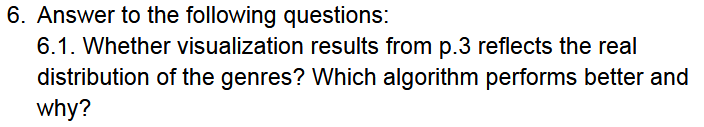

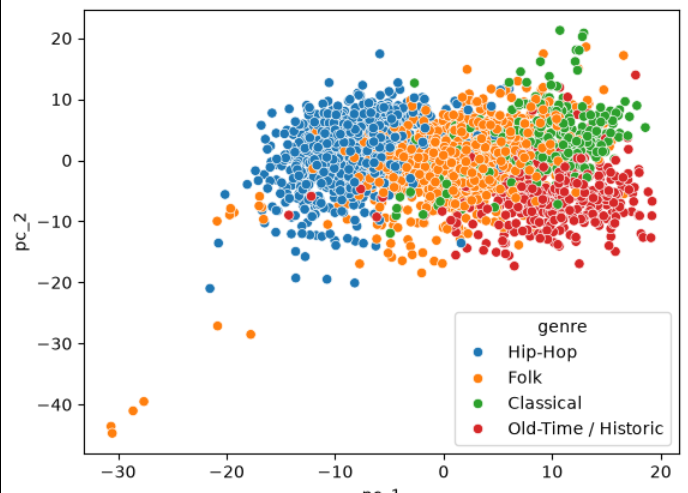

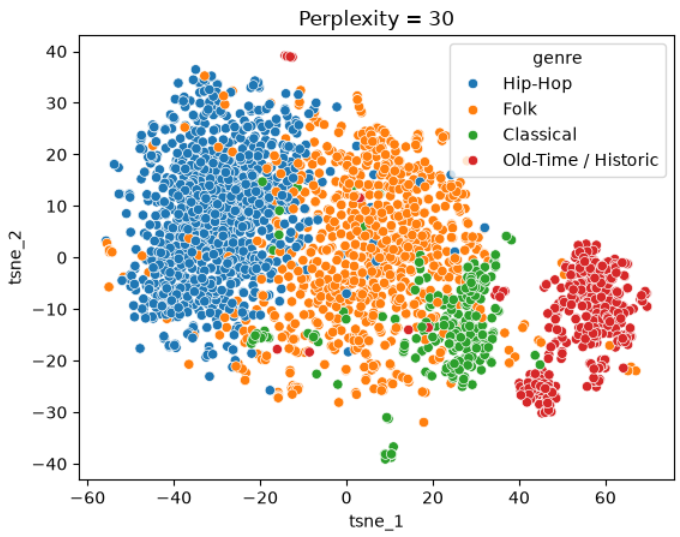

Both methods show the distribution of genres. In both visualizations, clouds of clusters intersect each other. The t-SNE clearly shows the separation of clusters, especially of the genre (Old-time/Historic). This is due to the fact that the algorithm is non-linear and can be applied to data with non-linear relationships, and therefore it is better suited to complex data.

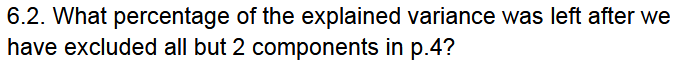

In [88]:
print(f"Explained variance percentage = {(cum_var_explained[2] * 100):.4f}%")


Explained variance percentage = 25.7992%


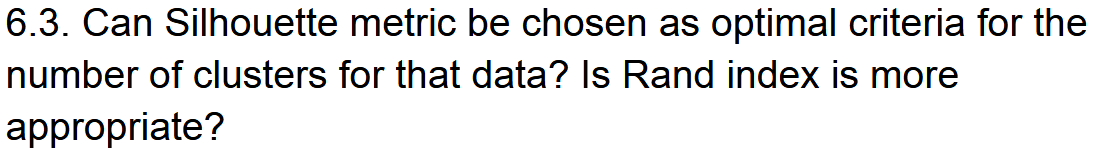

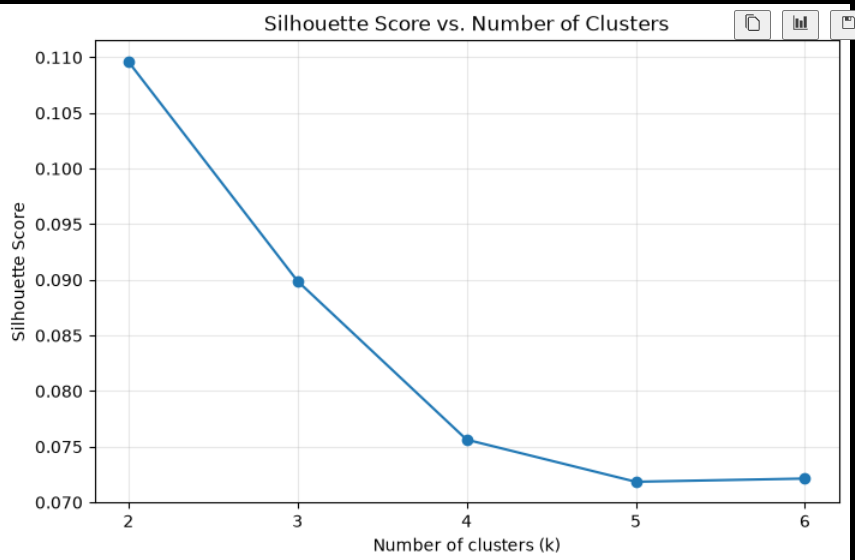

The silhouette metric reaches its maximum (at current levels) if the number of clusters is 2 and decreases with increasing number of clusters.  Initially, there were 4 clusters, so the silhouette metric is not an optimal criterion for determining the number of clusters. The situation with the Rand index looks better than with the silhouette metric, but in order to calculate the Rand index, we already need to know the initial partition, which means we already know the number of clusters.

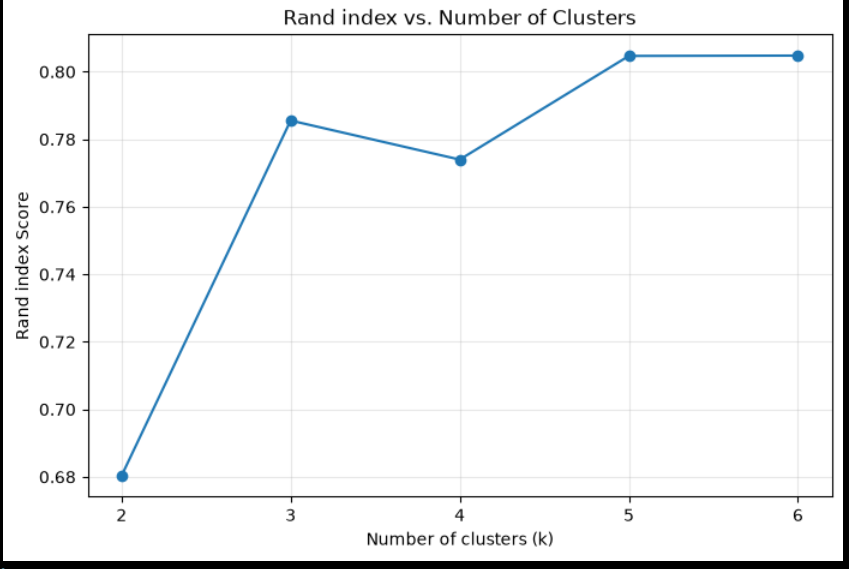

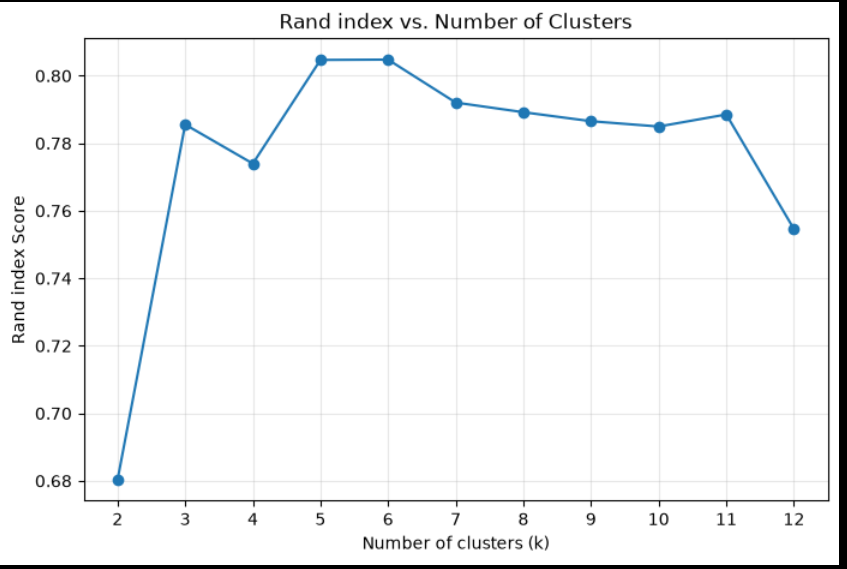

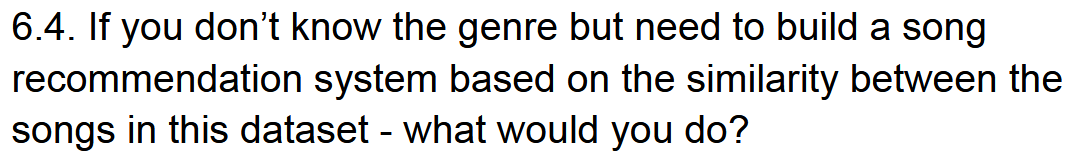

Split songs into clusters and recommend them from clusters